In [5]:
# -*- coding: utf-8 -*-

from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import scipy

In [6]:
# %% meta-data
fits.open('new-image.fits')
informatie = fits.getheader('new-image.fits')
print(informatie)

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                   16 / number of bits per data pixel                  NAXIS   =                    2 / number of data axes                            NAXIS1  =                 5496 / length of data axis 1                          NAXIS2  =                 3672 / length of data axis 2                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H BZERO   =                32768 / physical = BZERO + BSCALE*array_value          BSCALE  =                    1 / physical = BZERO + BSCALE*array_value          XBINNING=                    1 / Binning factor in width                        YBINNING=                    1 / Binning factor in height                       EXPOINUS=             10000000 / Exposur

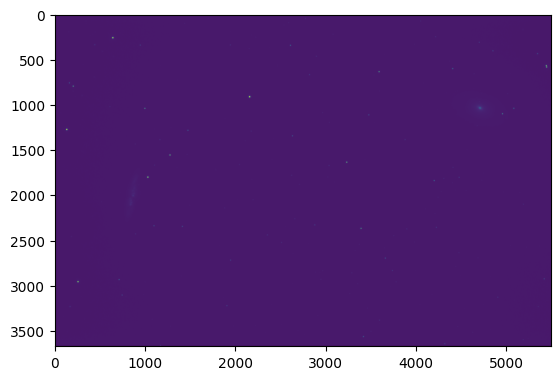

In [7]:
# %% data inladen en zichtbaar maken

data_file = fits.getdata('new-image.fits')
plt.imshow(data_file)
plt.show()

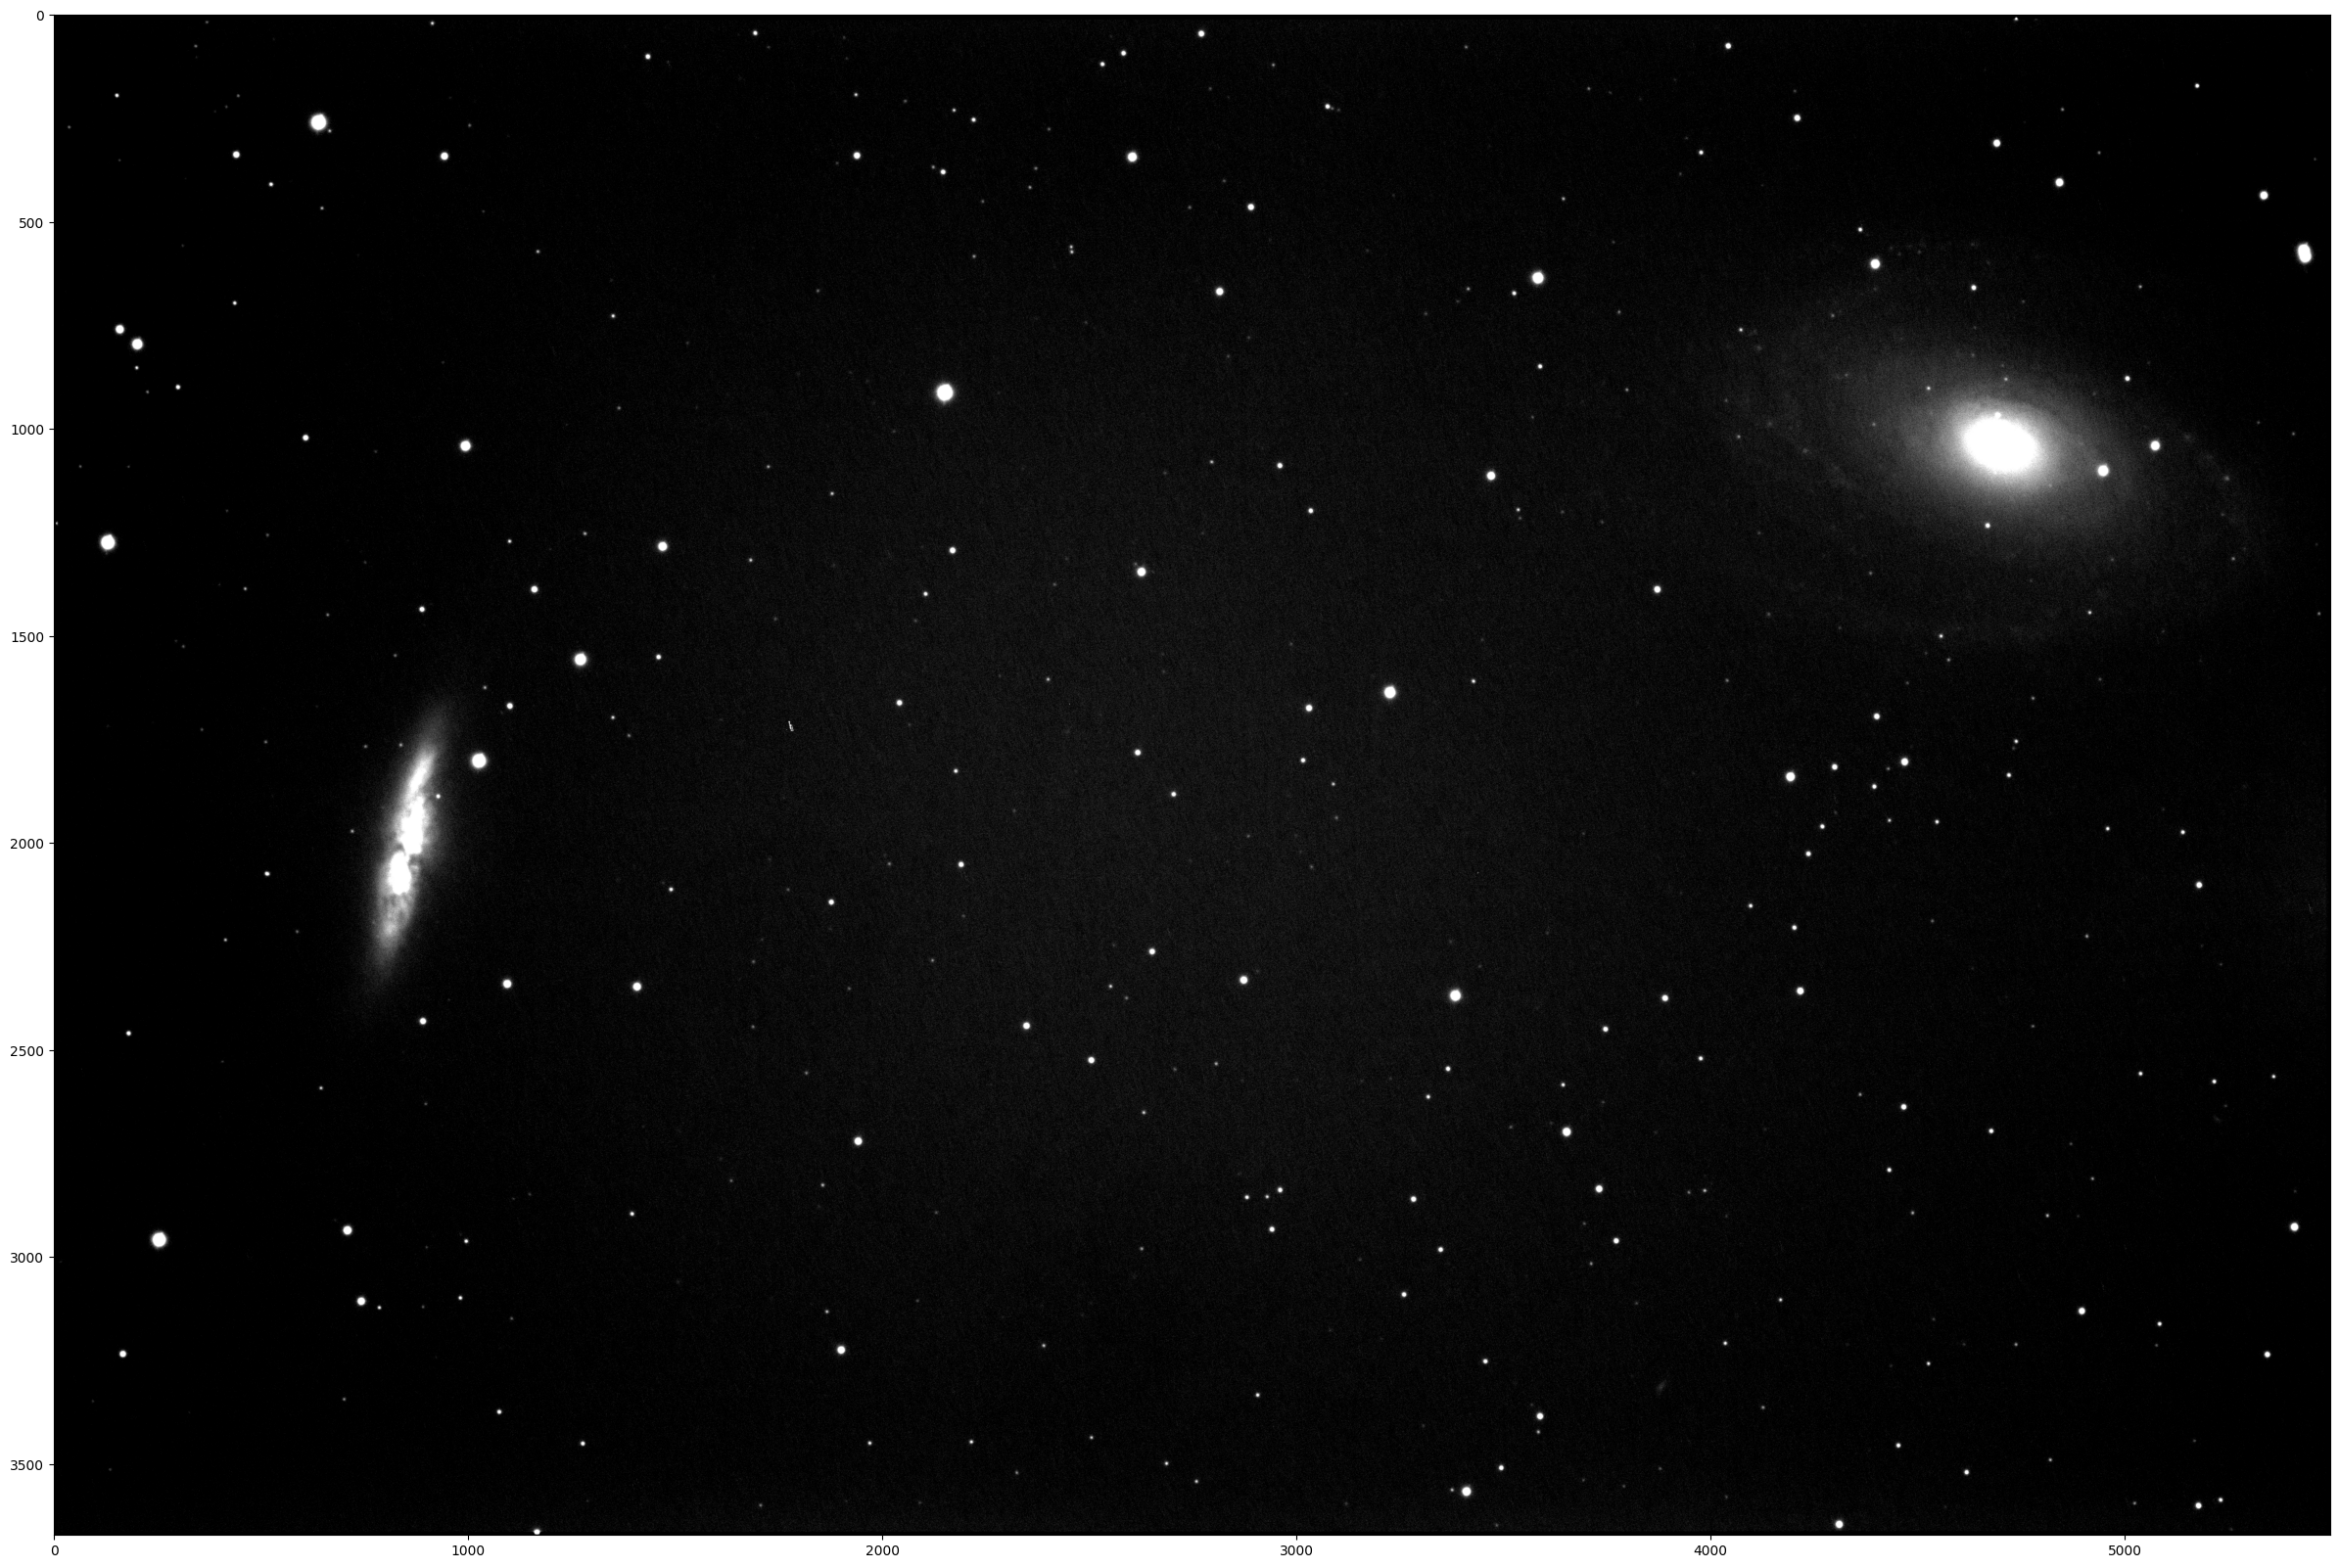

In [8]:
# %% Data beter zichtbaar maken: speel een beetje met de waarden voor vmin en vmax

plt.figure(figsize = (30,45))
plt.imshow(data_file, vmin = 4700, vmax= 5700, cmap= 'gray')
plt.show()

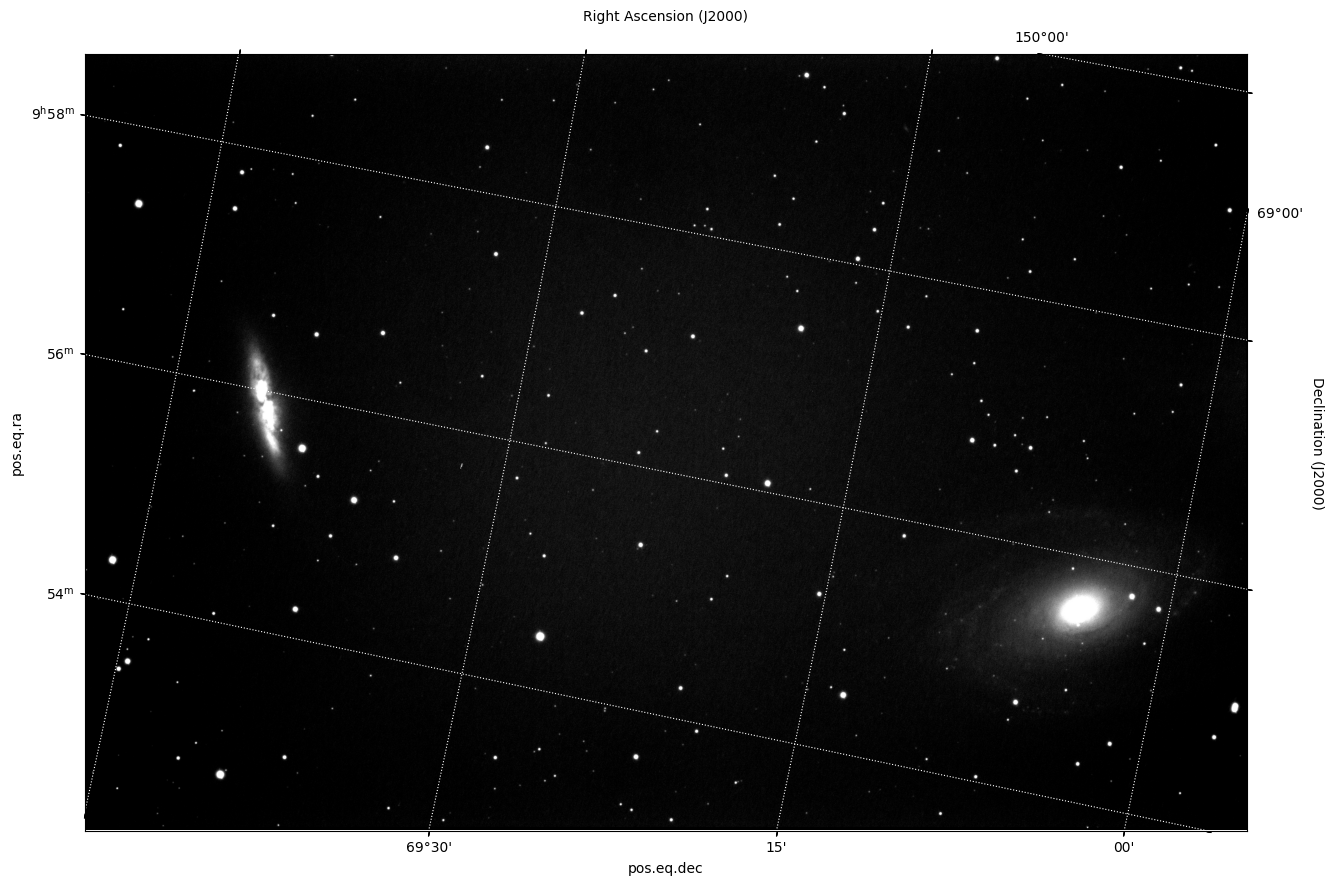

In [9]:
# %%Hemelcoordinaten uit de fits file plotten 
# (Let op: dit werkt alleen als je fits-file is 'geplatesolved'. Upload daarvoor je file op nova.astrometry.net en download dan het resultaat new-image.fits)

from astropy.wcs import WCS
plt.figure(figsize = (15,30))
wcs = WCS(informatie)
ax = plt.subplot(projection=wcs, label='overlays')
ax.imshow(data_file, vmin = 4700, vmax = 5700, origin='lower', cmap= 'gray')
overlay = ax.get_coords_overlay('fk5')
overlay.grid(color='white', ls='dotted')
overlay[0].set_axislabel('Right Ascension (J2000)')
overlay[1].set_axislabel('Declination (J2000)')
plt.show()

0d37m00.48s


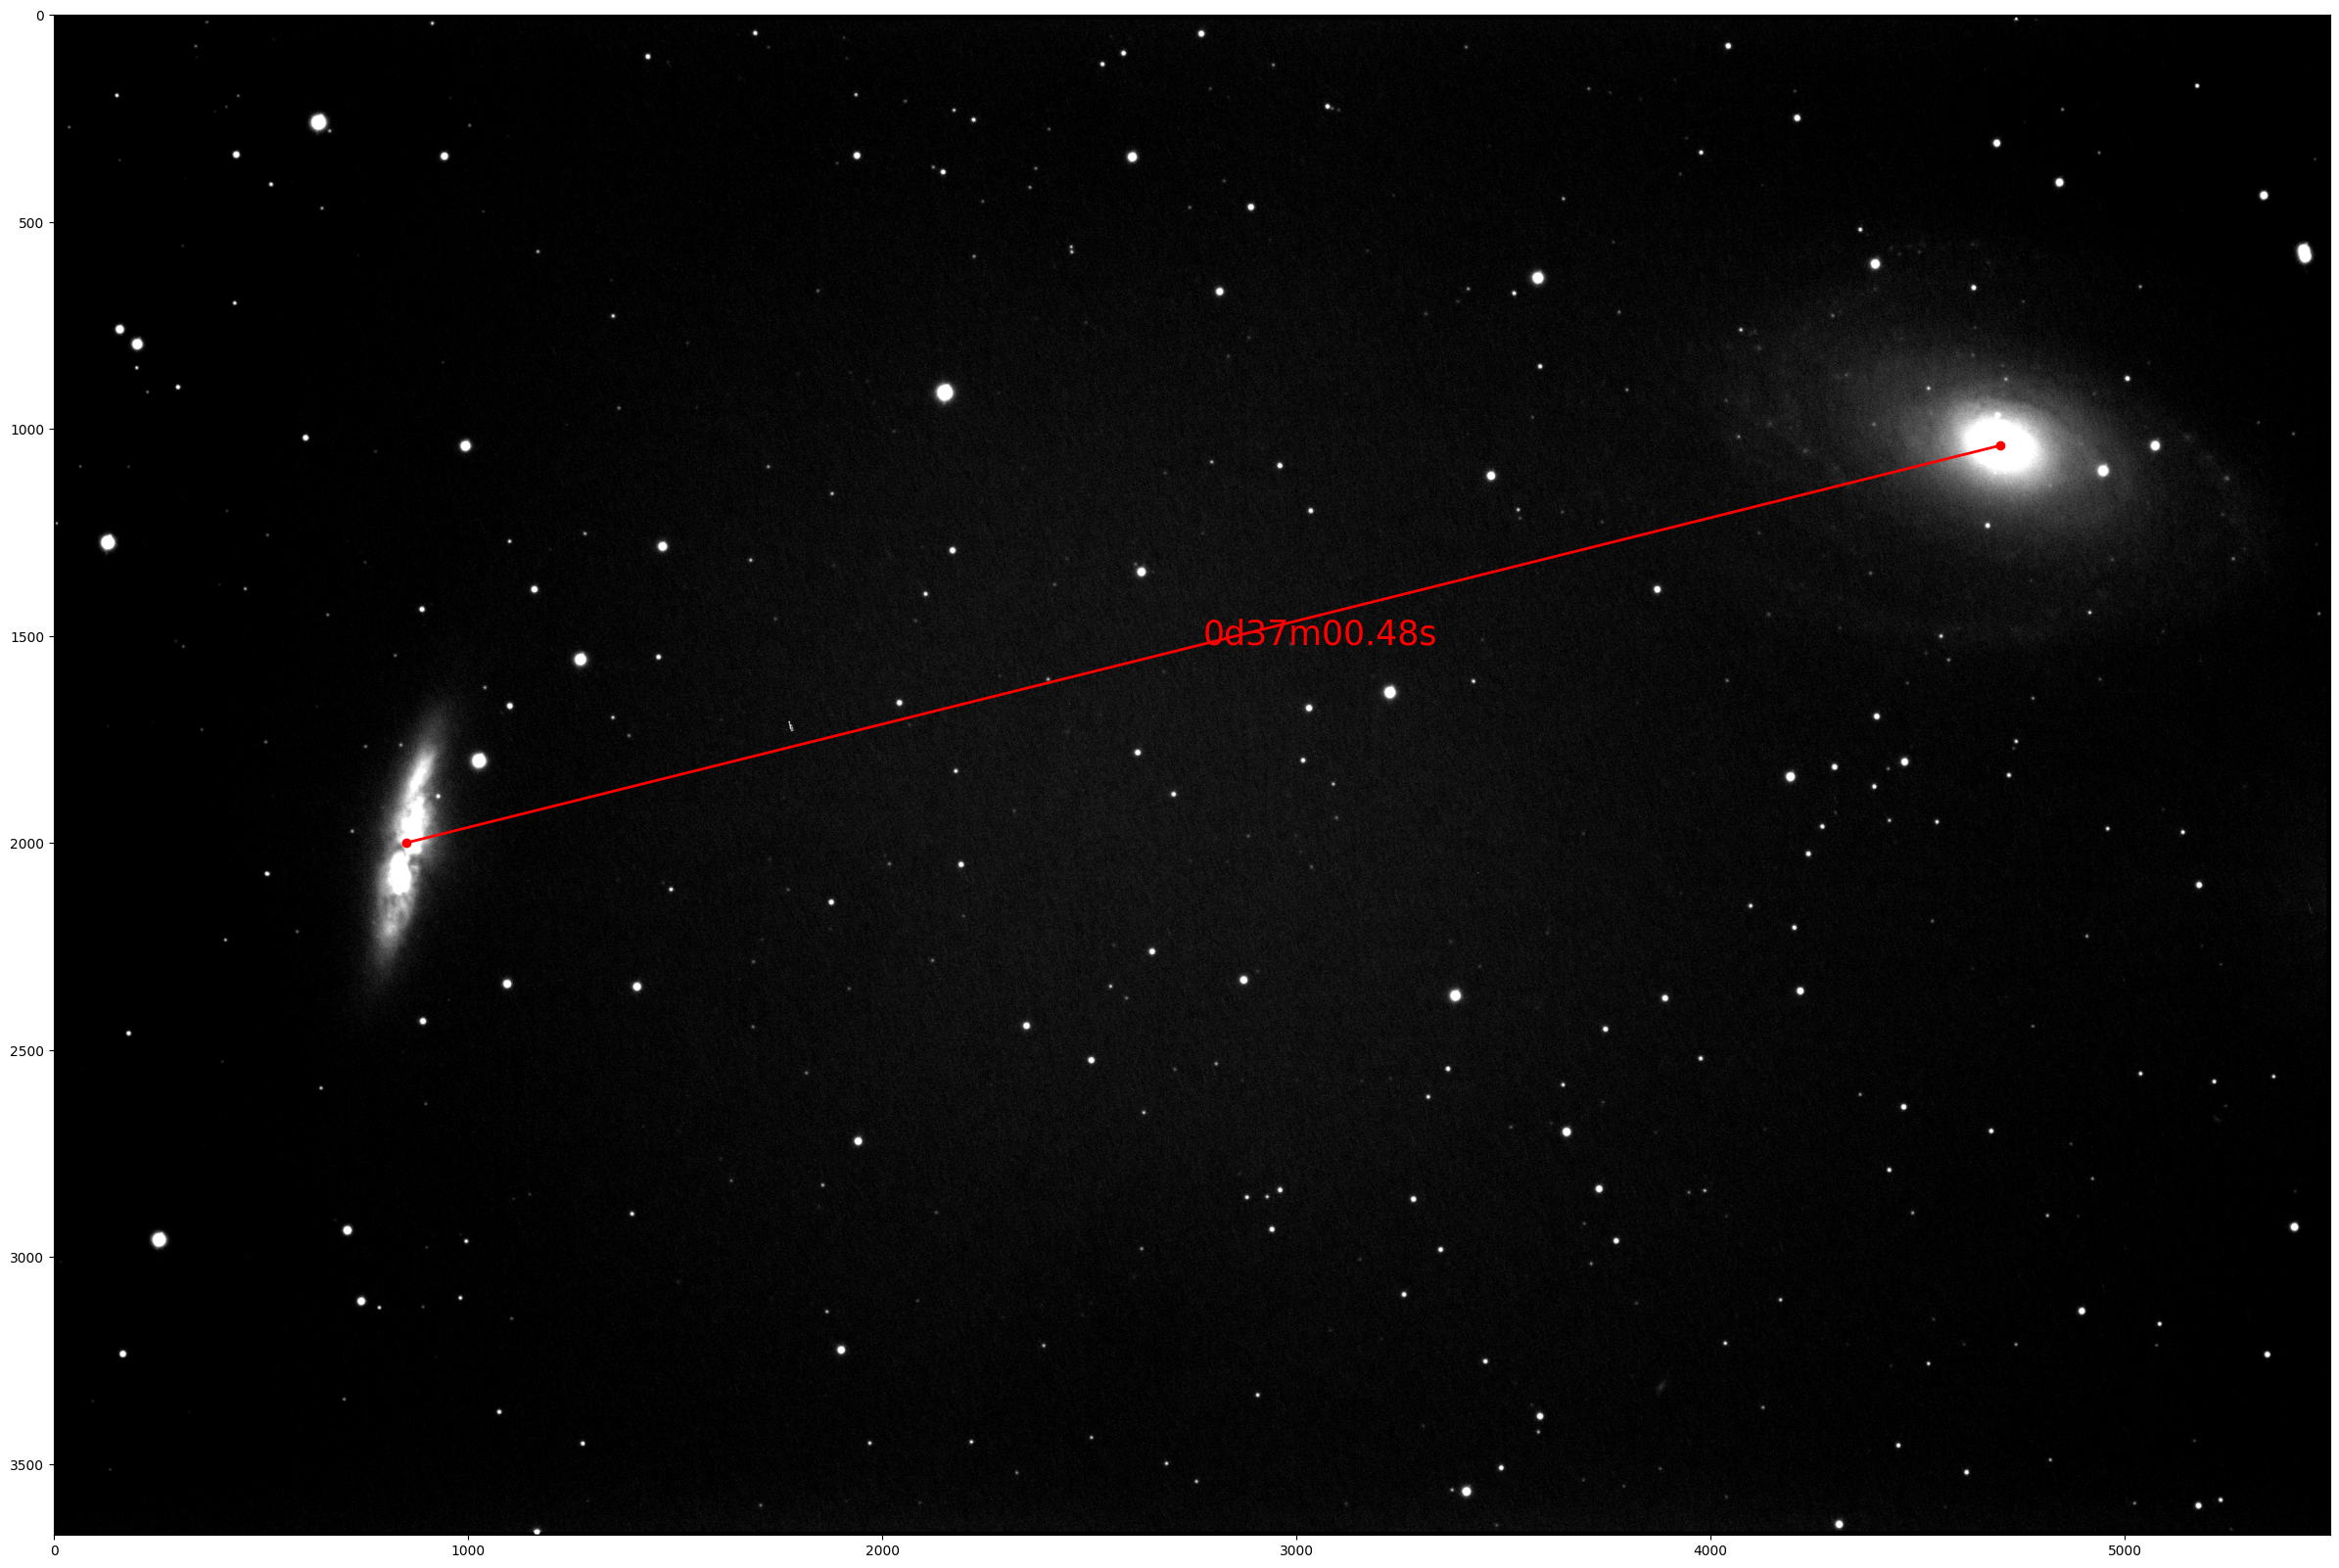

In [10]:
# %% hoekafstanden meten tussen 2 punten (mbv WCS-coordinated):


punt1_x = 850
punt1_y = 2000
sky_1 = wcs.pixel_to_world(punt1_x, punt1_y)

punt2_x = 4700
punt2_y = 1040
sky_2 = wcs.pixel_to_world(punt2_x, punt2_y)

distance = np.round(sky_1.separation(sky_2),4)
print(distance)

plt.figure( figsize = (30,45))
plt.imshow(data_file, vmin = 4700, vmax= 5700, cmap= 'gray')
plt.plot([punt1_x, punt2_x], [punt1_y, punt2_y], marker = 'o', c='red', lw=2)

plt.text((punt1_x+punt2_x)/2, (punt1_y+punt2_y)/2, distance, fontsize=25, c ='red')
plt.show()


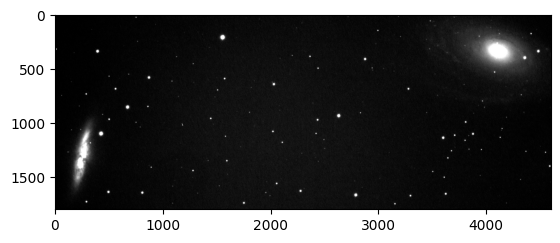

In [11]:
# %% een crop maken van je foto met 3000 < x < 4000 en 1500 < y < 2500

data_cropped = data_file[700:2500,600:5200]
plt.imshow(data_cropped, vmin = 4700, vmax= 5700, cmap= 'gray')
plt.show()

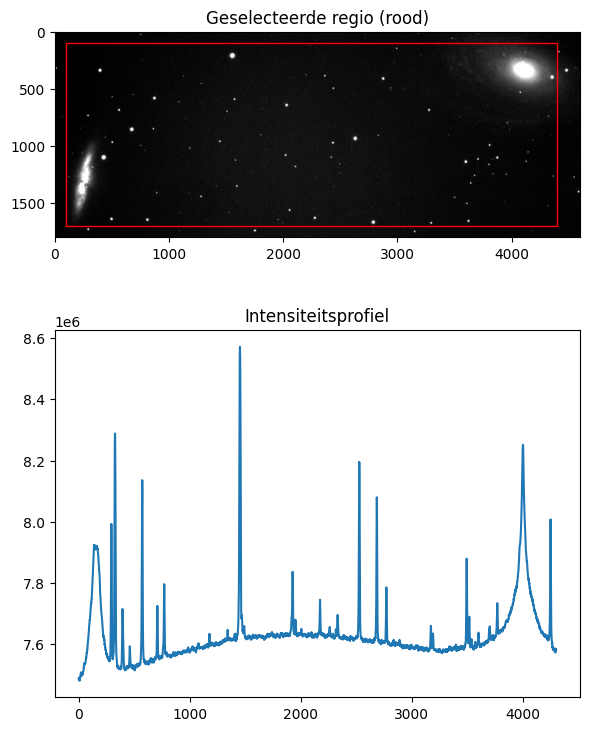

In [12]:
# %% Een intensiteitsplotje maken door de nevel heen:
    
from matplotlib.patches import Rectangle    

y_min = 100
y_max = 1700

x_min = 100
x_max = 4400

regio = data_cropped[y_min:y_max,x_min:x_max]
intensiteit = np.sum(regio, axis =0)

fig, axes = plt.subplots(2, 1, figsize=(6, 8))  # Twee subplots onder elkaar

# Eerste subplot: Beeld met rechthoek
axes[0].imshow(data_cropped, vmin=4700, vmax=5700, cmap='gray')
axes[0].add_patch(Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                            edgecolor='red', facecolor='none', lw=1))
axes[0].set_title("Geselecteerde regio (rood)")

# Tweede subplot: Intensiteitsprofiel
axes[1].plot(intensiteit)
axes[1].set_title("Intensiteitsprofiel")

plt.tight_layout()  # Zorgt voor nette schikking van de subplots
plt.show()

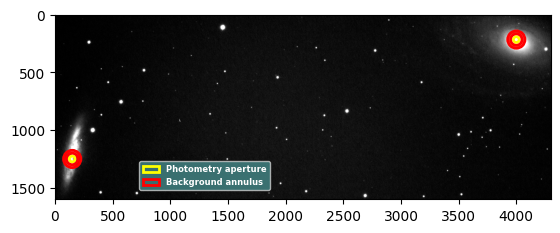

In [13]:
# %% Flux meten (zie https://photutils.readthedocs.io/en/latest/user_guide/aperture.html# )
# misschien moet je eerst photutils installeren ('pip install photutils')


from photutils.aperture import CircularAnnulus, CircularAperture, aperture_photometry, ApertureStats


data_fotometrie = data_cropped[100:1700,100:4400]

# 2 posities definieren:

positions = [(150, 1250),(4000, 215)]
aperture = CircularAperture(positions, r=25)
annulus_aperture = CircularAnnulus(positions, r_in=50, r_out=75)


# plaatje maken

plt.imshow(data_fotometrie, vmin = 4700, vmax= 5700, cmap= 'gray')

ap_patches = aperture.plot(color='yellow', lw=2,
                           label='Photometry aperture')
ann_patches = annulus_aperture.plot(color='red', lw=2,
                                    label='Background annulus')
handles = (ap_patches[0], ann_patches[0])
plt.legend(loc=(0.17, 0.05), facecolor='#458989', labelcolor='white',
           handles=handles, prop={'weight': 'bold', 'size': 6})
plt.show()

In [14]:
phot_table = aperture_photometry(data_fotometrie, aperture)

aperstats = ApertureStats(data_fotometrie, annulus_aperture)
bkg_mean = aperstats.mean
aperture_area = aperture.area_overlap(data_fotometrie)
total_bkg = bkg_mean * aperture_area

# %% Fotometrie


calibration_constant  = 26.57
phot_bkgsub = phot_table['aperture_sum'] - total_bkg
phot_table['total_bkg'] = total_bkg
phot_table['aperture_sum_bkgsub'] = phot_bkgsub
phot_table['instrumental magnitude'] = -2.5*np.log10(phot_bkgsub)
phot_table['calibrated magnitude'] = -2.5*np.log10(phot_bkgsub) + calibration_constant
for col in phot_table.colnames:
    phot_table[col].info.format = '%.8g'  # for consistent table output
print(phot_table)

 id xcenter ycenter ... instrumental magnitude calibrated magnitude
--- ------- ------- ... ---------------------- --------------------
  1     150    1250 ...             -14.921128            11.648872
  2    4000     215 ...             -16.917412            9.6525879


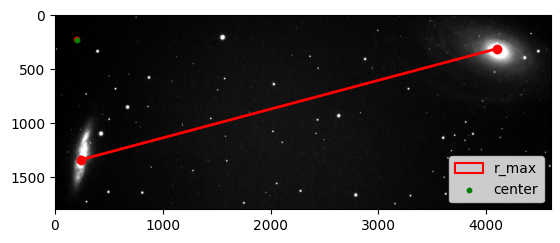

C:\Users\jjsho\AppData\Local\Temp\ipykernel_14904\1329921404.py:33: RuntimeWarning: divide by zero encountered in divide
  bin_areas /= bin_means


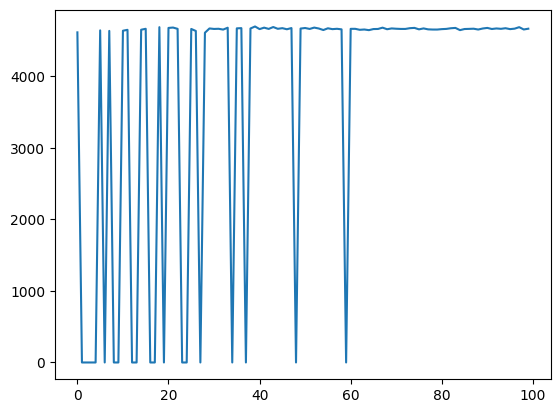

In [15]:
# Verondersteld dat 'data_cropped' al gedefinieerd is
height, width = data_cropped.shape
center = (205, 228)

# Bereken radiale afstand
y, x = np.indices((height, width))
r = np.sqrt((x - center[0]) ** 2 + (y - center[1]) ** 2)

# Definieer radiale bins
r_max = 20
num_bins = 100
bin_edges = np.linspace(0, r_max, num_bins + 1)
bin_indices = np.digitize(r, bin_edges) - 1
punt_x=240
punt4_x=4100
punt_y=1340
punt4_y=310

fig, ax = plt.subplots()
im = ax.imshow(data_cropped, vmin=4700, vmax=5700, cmap='gray', origin='upper')
circle_outer = plt.Circle(center, r_max, color='red', fill=False, linewidth=1.5, label = 'r_max')
plt.plot([punt_x, punt4_x], [punt_y, punt4_y], marker = 'o', c='red', lw=2)
ax.add_patch(circle_outer)
ax.scatter(center[0], center[1], c='green', s=10, label = 'center')
plt.legend()
plt.show()

# finding the mean flux values for each bin
bin_means = np.array([data_cropped[bin_indices == i].mean() if np.any(bin_indices == i) else 0 for i in range(num_bins)])

# diving each bin flux sum by its area
bin_areas = np.pi * (bin_edges[:-1]**2-bin_edges[1:]**2 )
bin_areas /= bin_means

plt.plot(bin_means)
# plt.yscale('log')
plt.show()


C:\Users\jjsho\AppData\Local\Temp\ipykernel_14904\100281148.py:16: UserWarning: linewidths is ignored by contourf
  contours = ax.contourf(data_smooth, levels=levels, cmap="viridis", linewidths=0.8)


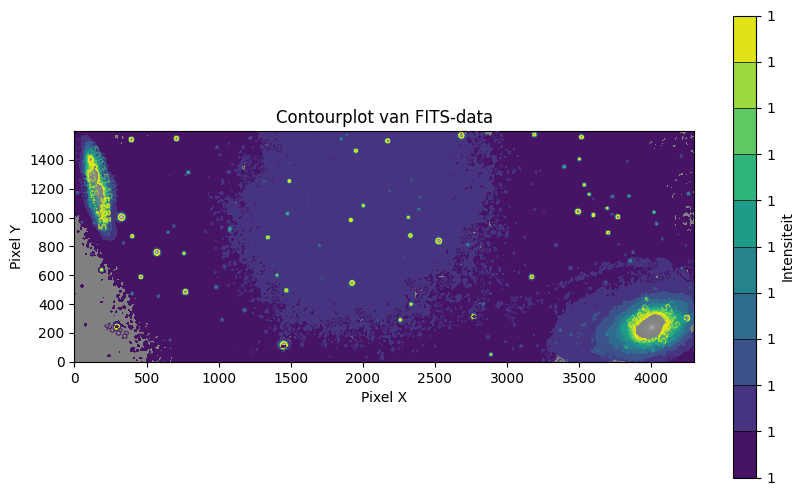

In [ ]:
# %% contourplot
from scipy.ndimage import gaussian_filter

super_crop = data_cropped[100:1700,100:4400]
fig, ax = plt.subplots(figsize=(10, 6))

#doordat de sterrenstelsels rond 2000 liggen en de felle sterren opp 65000 bepalen we onze min en max waarde
# op basis van procent
data_smooth = gaussian_filter(super_crop, sigma=5)

min_waarde = np.percentile(data_smooth, 5)
max_waarde = np.percentile(data_smooth, 99)
#lineaire stapjes van 20 tussen de min-max waarde
levels = np.linspace(min_waarde, max_waarde, 11)

contours = ax.contourf(data_smooth, levels=levels, cmap="viridis", linewidths=0.8)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.0f")  # Labels op contourlijnen
ax.imshow(data_smooth, cmap="gray", origin="lower", alpha=0.5)  # Transparante achtergrond

cbar = plt.colorbar(contours, ax=ax, label="Intensiteit")
cbar.set_ticks(levels)
cbar.set_ticklabels([f"{int(1)}" for l in levels])

cbar.ax.hlines(levels, *cbar.ax.get_xlim(), colors='black', linewidths=0.5)

ax.set_title("Contourplot van FITS-data")
ax.set_xlabel("Pixel X")
ax.set_ylabel("Pixel Y")
plt.show()

In [26]:
from astropy.coordinates import SkyCoord
from astropy import units as u


coords_m81 = SkyCoord(ra='09h55m33.2s', dec='+69d03m55s', frame='fk5')
coords_m82 = SkyCoord(ra='09h55m52.2s', dec='+69d40m47s', frame='fk5')

angular_sep = coords_m81.separation(coords_m82)
print(f"Angular Separation: {angular_sep.degree:.4f} degrees")

dist_to_group = 3.6 * u.Mpc
physical_dist = (angular_sep.to(u.rad).value * dist_to_group).to(u.kpc)
print(f"Estimated Physical Separation: {physical_dist:.2f} kpc")

mass_m81 = 7.2e10
mass_m82 = 1.0e10
radius_m82 = 5.0

roche_limit = radius_m82 * (2 * (mass_m81 / mass_m82))**(1/3)
print(f"Calculated Roche Limit: {roche_limit:.2f} kpc")

if physical_dist < roche_limit * u.kpc:
    print("\nRESULT: Physical separation is WITHIN the Roche limit.")
    print("Likelihood of gas exchange/tidal stripping: HIGH.")
else:
    print("\nRESULT: Physical separation is OUTSIDE the Roche limit.")
    print("Likelihood of immediate gas exchange: LOW (current state).")

Angular Separation: 0.6151 degrees
Estimated Physical Separation: 38.65 kpc kpc
Calculated Roche Limit: 12.16 kpc

RESULT: Physical separation is OUTSIDE the Roche limit.
Likelihood of immediate gas exchange: LOW (current state).
